# 🧠 ADHD & Sex Prediction from Brain Connectome Data
### A Comprehensive Machine Learning Analysis for WiDS Datathon 2025

**Team:** KLE B Pyoneers  
**Objective:** Predict ADHD diagnosis and biological sex using brain functional connectome matrices and demographic metadata

---

## 📋 Table of Contents
1. [Data Loading & Initial Setup](#data-loading)
2. [Exploratory Data Analysis](#eda)
3. [Data Preprocessing](#preprocessing)
4. [Feature Engineering](#feature-engineering)
5. [Model Training & Evaluation](#modeling)
6. [Results & Visualizations](#results)
7. [Final Predictions](#predictions)

## 📚 Import Required Libraries

In [21]:
# Core libraries
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.gridspec import GridSpec
import warnings
warnings.filterwarnings('ignore')

# Set matplotlib style for better plots
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 10

# Machine Learning libraries
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer, KNNImputer
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold, RFECV
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, KFold, train_test_split
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix, classification_report

# For handling imbalanced data
from imblearn.over_sampling import SMOTE
from collections import Counter

# Advanced ML models
try:
    import xgboost as xgb
    xgboost_available = True
    print("✅ XGBoost loaded successfully")
except ImportError:
    print("❌ XGBoost not available")
    xgboost_available = False

try:
    from catboost import CatBoostClassifier
    catboost_available = True
    print("✅ CatBoost loaded successfully")
except ImportError:
    print("❌ CatBoost not available")
    catboost_available = False

# Utility libraries
import random
import string
import os

# Configuration
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

print("🎯 All libraries imported successfully!")

✅ XGBoost loaded successfully
✅ CatBoost loaded successfully
🎯 All libraries imported successfully!


## 🔧 Configuration & Constants

In [ ]:
# Global configuration
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

# Model parameters
REPEATS = 5
FOLDS = 5
PCA_VARIANCE_THRESHOLD = 0.95
VARIANCE_THRESHOLD = 0.01

# Data paths
BASE_PATH = "kaggle/input/widsdatathon2025/"

print("🔧 Configuration set successfully!")
print(f"📊 Random Seed: {SEED}")
print(f"📈 PCA Variance Retention: {PCA_VARIANCE_THRESHOLD}")
print(f"📉 Variance Threshold: {VARIANCE_THRESHOLD}")

🔧 Configuration set successfully!
📊 Random Seed: 42
📈 PCA Variance Retention: 0.95
📉 Variance Threshold: 0.01


<a id="data-loading"></a>
# 📁 Data Loading & Initial Setup

Let's load all the required datasets and perform initial data merging.

In [3]:
def load_datasets(base_path):
    """
    Load all training and test datasets
    """
    print("📥 Loading datasets...")
    
    # Training data
    train_categorical = pd.read_excel(base_path + "TRAIN_NEW/TRAIN_CATEGORICAL_METADATA_new.xlsx")
    train_quantitative = pd.read_excel(base_path + "TRAIN_NEW/TRAIN_QUANTITATIVE_METADATA_new.xlsx")
    train_connectome = pd.read_csv(base_path + 'TRAIN_NEW/TRAIN_FUNCTIONAL_CONNECTOME_MATRICES_new_36P_Pearson.csv')
    train_solutions = pd.read_excel(base_path + "TRAIN_NEW/TRAINING_SOLUTIONS.xlsx")
    
    # Test data
    test_quantitative = pd.read_excel(base_path + "TEST/TEST_QUANTITATIVE_METADATA.xlsx")
    test_categorical = pd.read_excel(base_path + "TEST/TEST_CATEGORICAL.xlsx")
    test_connectome = pd.read_csv(base_path + "TEST/TEST_FUNCTIONAL_CONNECTOME_MATRICES.csv")
    
    print("✅ All datasets loaded successfully!")
    
    return {
        'train_cat': train_categorical,
        'train_quant': train_quantitative,
        'train_conn': train_connectome,
        'train_sol': train_solutions,
        'test_cat': test_categorical,
        'test_quant': test_quantitative,
        'test_conn': test_connectome
    }

# Load datasets
datasets = load_datasets(BASE_PATH)

# Display dataset shapes
print("\n📊 Dataset Shapes:")
for name, df in datasets.items():
    print(f"  {name:12}: {df.shape}")

📥 Loading datasets...
✅ All datasets loaded successfully!

📊 Dataset Shapes:
  train_cat   : (1213, 10)
  train_quant : (1213, 19)
  train_conn  : (1213, 19901)
  train_sol   : (1213, 3)
  test_cat    : (304, 10)
  test_quant  : (304, 19)
  test_conn   : (304, 19901)


In [4]:
def merge_datasets(datasets):
    """
    Merge training and test datasets
    """
    print("🔗 Merging datasets...")
    
    # Merge training data
    train_combined = pd.merge(datasets['train_quant'], datasets['train_cat'], on="participant_id", how="left")
    train_combined = pd.merge(train_combined, datasets['train_conn'], on="participant_id", how="left")
    train_combined = pd.merge(train_combined, datasets['train_sol'], on="participant_id", how="left")
    train_combined.set_index("participant_id", inplace=True)
    
    # Merge test data
    test_combined = pd.merge(datasets['test_quant'], datasets['test_cat'], on="participant_id", how="left")
    test_combined = pd.merge(test_combined, datasets['test_conn'], on="participant_id", how="left")
    test_combined.set_index("participant_id", inplace=True)
    
    print("✅ Datasets merged successfully!")
    print(f"📊 Training data shape: {train_combined.shape}")
    print(f"📊 Test data shape: {test_combined.shape}")
    
    return train_combined, test_combined

# Merge datasets
train_data, test_data = merge_datasets(datasets)

🔗 Merging datasets...
✅ Datasets merged successfully!
📊 Training data shape: (1213, 19929)
📊 Test data shape: (304, 19927)


<a id="eda"></a>
# 🔍 Exploratory Data Analysis

Let's explore our data with comprehensive visualizations.

In [5]:
# Define variable categories
categorical_vars = [
    "ColorVision_CV_Score", "APQ_P_APQ_P_CP", "SDQ_SDQ_Conduct_Problems", 
    "SDQ_SDQ_Emotional_Problems", "SDQ_SDQ_Generating_Impact", "SDQ_SDQ_Hyperactivity", 
    "SDQ_SDQ_Peer_Problems", "SDQ_SDQ_Prosocial", 'Basic_Demos_Enroll_Year', 
    'Basic_Demos_Study_Site', 'PreInt_Demos_Fam_Child_Ethnicity', 
    'PreInt_Demos_Fam_Child_Race', 'MRI_Track_Scan_Location', 
    'Barratt_Barratt_P1_Edu', 'Barratt_Barratt_P1_Occ', 
    'Barratt_Barratt_P2_Edu', 'Barratt_Barratt_P2_Occ'
]

numerical_vars = [
    "EHQ_EHQ_Total", "MRI_Track_Age_at_Scan", "APQ_P_APQ_P_ID", "APQ_P_APQ_P_INV", 
    "APQ_P_APQ_P_OPD", "APQ_P_APQ_P_PM", "APQ_P_APQ_P_PP", "SDQ_SDQ_Difficulties_Total", 
    "SDQ_SDQ_Externalizing", "SDQ_SDQ_Internalizing"
]

# Identify connectome variables
exclude_vars = set(categorical_vars + numerical_vars + ['ADHD_Outcome', 'Sex_F'])
connectome_vars = [col for col in train_data.columns if col not in exclude_vars]

print("🧩 Variable Categories:")
print(f"  📋 Categorical Variables: {len(categorical_vars)}")
print(f"  📊 Numerical Variables: {len(numerical_vars)}")
print(f"  🧠 Connectome Variables: {len(connectome_vars)}")

🧩 Variable Categories:
  📋 Categorical Variables: 17
  📊 Numerical Variables: 10
  🧠 Connectome Variables: 19900


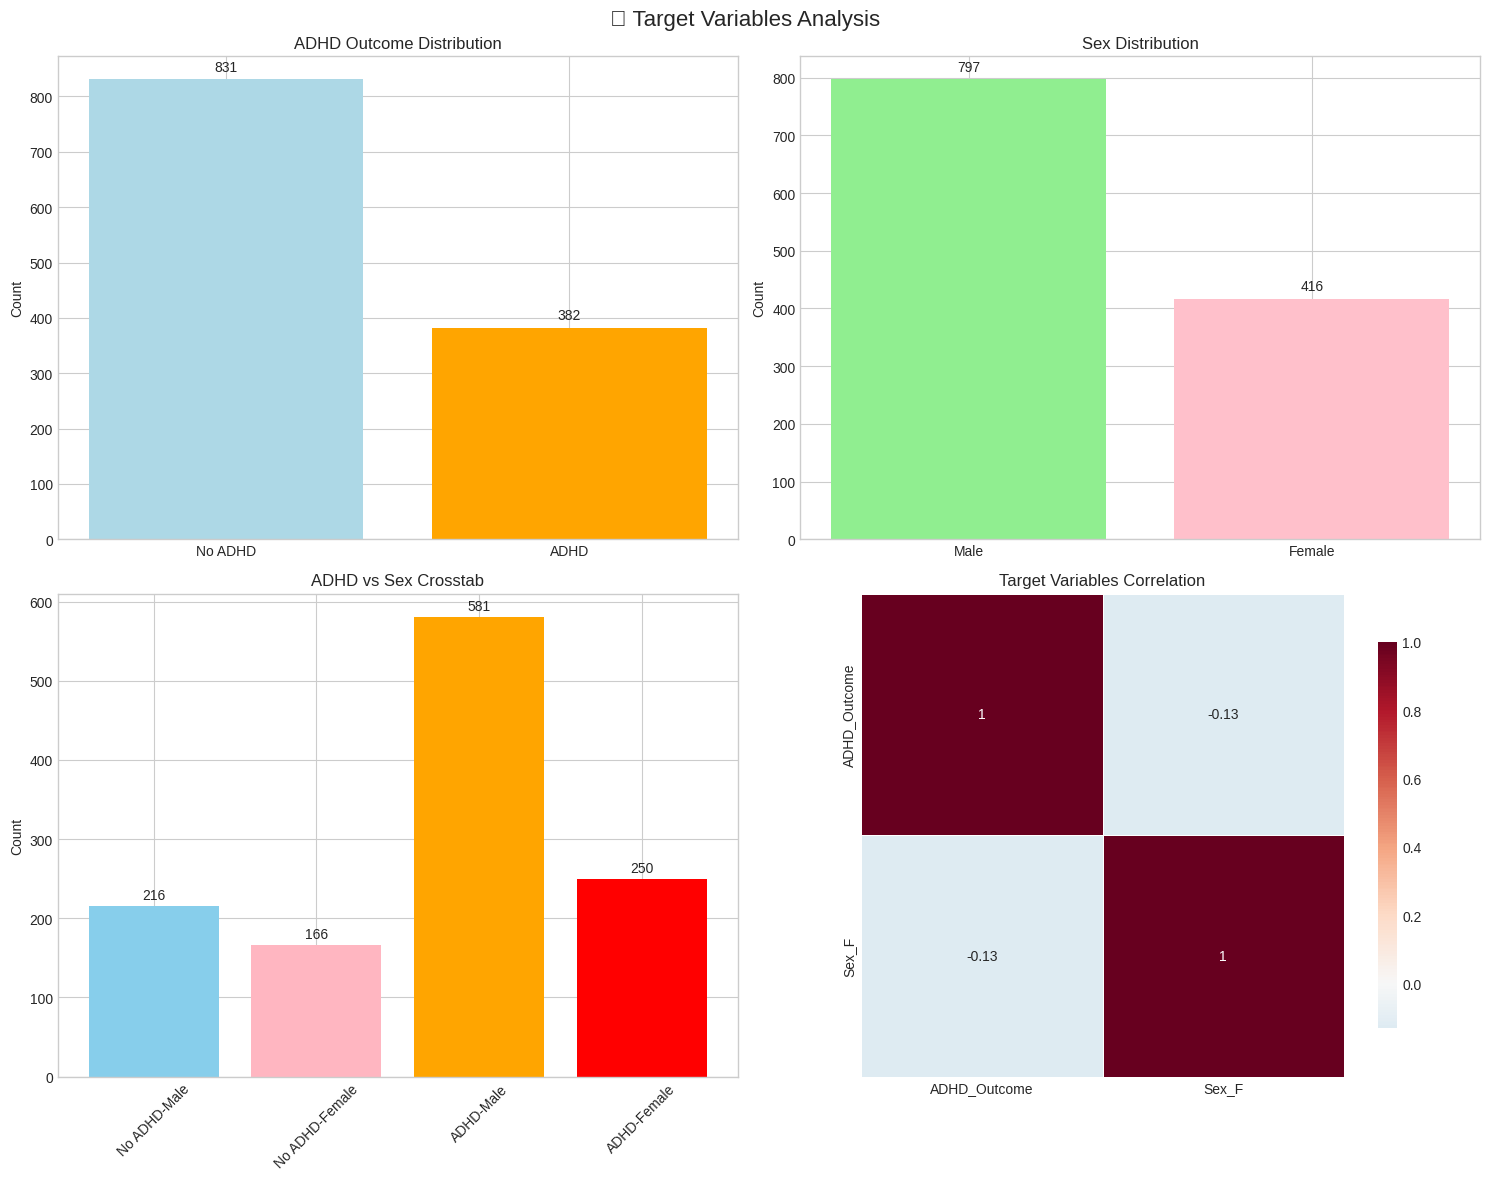

📊 Target Variable Statistics:
  ADHD Distribution: {1: 831, 0: 382}
  Sex Distribution: {0: 797, 1: 416}
  ADHD-Sex Correlation: -0.131


In [6]:
def create_target_distribution_plot(train_data):
    """
    Create comprehensive target variable distribution plots using matplotlib
    """
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    
    # ADHD distribution
    adhd_counts = train_data['ADHD_Outcome'].value_counts()
    axes[0, 0].bar(['No ADHD', 'ADHD'], adhd_counts.values, color=['lightblue', 'orange'])
    axes[0, 0].set_title('ADHD Outcome Distribution')
    axes[0, 0].set_ylabel('Count')
    for i, v in enumerate(adhd_counts.values):
        axes[0, 0].text(i, v + 10, str(v), ha='center', va='bottom')
    
    # Sex distribution
    sex_counts = train_data['Sex_F'].value_counts()
    axes[0, 1].bar(['Male', 'Female'], sex_counts.values, color=['lightgreen', 'pink'])
    axes[0, 1].set_title('Sex Distribution')
    axes[0, 1].set_ylabel('Count')
    for i, v in enumerate(sex_counts.values):
        axes[0, 1].text(i, v + 10, str(v), ha='center', va='bottom')
    
    # Crosstab
    crosstab = pd.crosstab(train_data['ADHD_Outcome'], train_data['Sex_F'])
    crosstab_values = crosstab.values.flatten()
    axes[1, 0].bar(['No ADHD-Male', 'No ADHD-Female', 'ADHD-Male', 'ADHD-Female'],
                   crosstab_values, color=['skyblue', 'lightpink', 'orange', 'red'])
    axes[1, 0].set_title('ADHD vs Sex Crosstab')
    axes[1, 0].set_ylabel('Count')
    axes[1, 0].tick_params(axis='x', rotation=45)
    for i, v in enumerate(crosstab_values):
        axes[1, 0].text(i, v + 5, str(v), ha='center', va='bottom')
    
    # Correlation heatmap
    corr_matrix = train_data[['ADHD_Outcome', 'Sex_F']].corr()
    sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', center=0, ax=axes[1, 1],
                square=True, linewidths=0.5, cbar_kws={"shrink": .8})
    axes[1, 1].set_title('Target Variables Correlation')
    
    plt.suptitle('🎯 Target Variables Analysis', fontsize=16, y=0.98)
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print("📊 Target Variable Statistics:")
    print(f"  ADHD Distribution: {dict(adhd_counts)}")
    print(f"  Sex Distribution: {dict(sex_counts)}")
    print(f"  ADHD-Sex Correlation: {train_data['ADHD_Outcome'].corr(train_data['Sex_F']):.3f}")
    
    return crosstab

# Create target distribution plot
crosstab_result = create_target_distribution_plot(train_data)

🔍 Missing Values Analysis


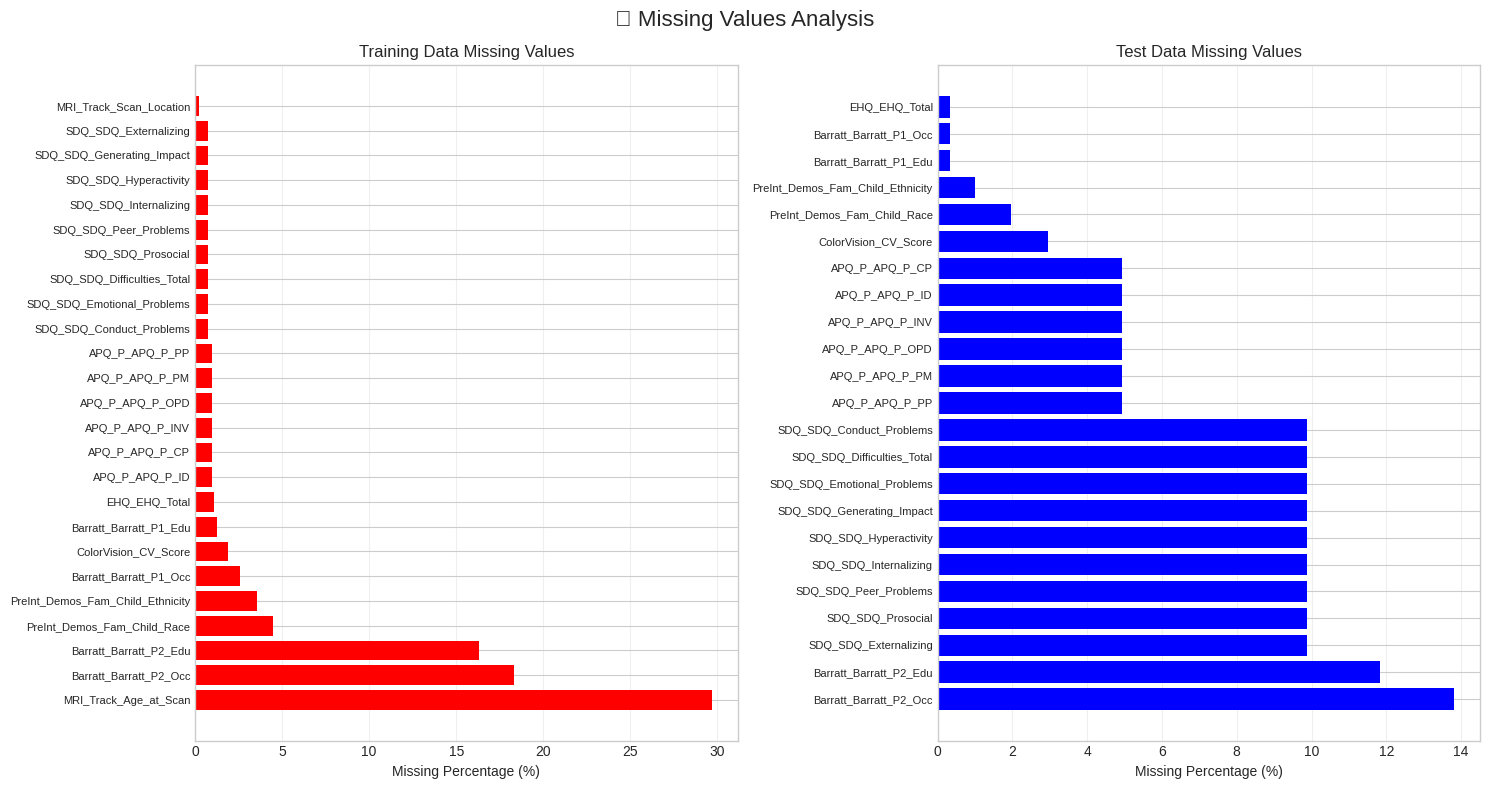

  📈 Training data: 25 columns with missing values
  📈 Test data: 23 columns with missing values


In [7]:
def analyze_missing_values(train_data, test_data):
    """
    Comprehensive missing value analysis with visualizations using matplotlib
    """
    print("🔍 Missing Values Analysis")
    
    # Calculate missing percentages
    train_missing = (train_data.isnull().sum() / len(train_data) * 100).sort_values(ascending=False)
    test_missing = (test_data.isnull().sum() / len(test_data) * 100).sort_values(ascending=False)
    
    # Filter columns with missing values
    train_missing_filtered = train_missing[train_missing > 0]
    test_missing_filtered = test_missing[test_missing > 0]
    
    if len(train_missing_filtered) > 0 or len(test_missing_filtered) > 0:
        fig, axes = plt.subplots(1, 2, figsize=(15, 8))
        
        # Training data missing values
        if len(train_missing_filtered) > 0:
            axes[0].barh(range(len(train_missing_filtered)), train_missing_filtered.values, color='red')
            axes[0].set_yticks(range(len(train_missing_filtered)))
            axes[0].set_yticklabels(train_missing_filtered.index, fontsize=8)
            axes[0].set_xlabel('Missing Percentage (%)')
            axes[0].set_title('Training Data Missing Values')
            axes[0].grid(axis='x', alpha=0.3)
        
        # Test data missing values
        if len(test_missing_filtered) > 0:
            axes[1].barh(range(len(test_missing_filtered)), test_missing_filtered.values, color='blue')
            axes[1].set_yticks(range(len(test_missing_filtered)))
            axes[1].set_yticklabels(test_missing_filtered.index, fontsize=8)
            axes[1].set_xlabel('Missing Percentage (%)')
            axes[1].set_title('Test Data Missing Values')
            axes[1].grid(axis='x', alpha=0.3)
        
        plt.suptitle('📊 Missing Values Analysis', fontsize=16)
        plt.tight_layout()
        plt.show()
    
    print(f"  📈 Training data: {len(train_missing_filtered)} columns with missing values")
    print(f"  📈 Test data: {len(test_missing_filtered)} columns with missing values")
    
    return train_missing_filtered, test_missing_filtered

# Analyze missing values
train_missing, test_missing = analyze_missing_values(train_data, test_data)

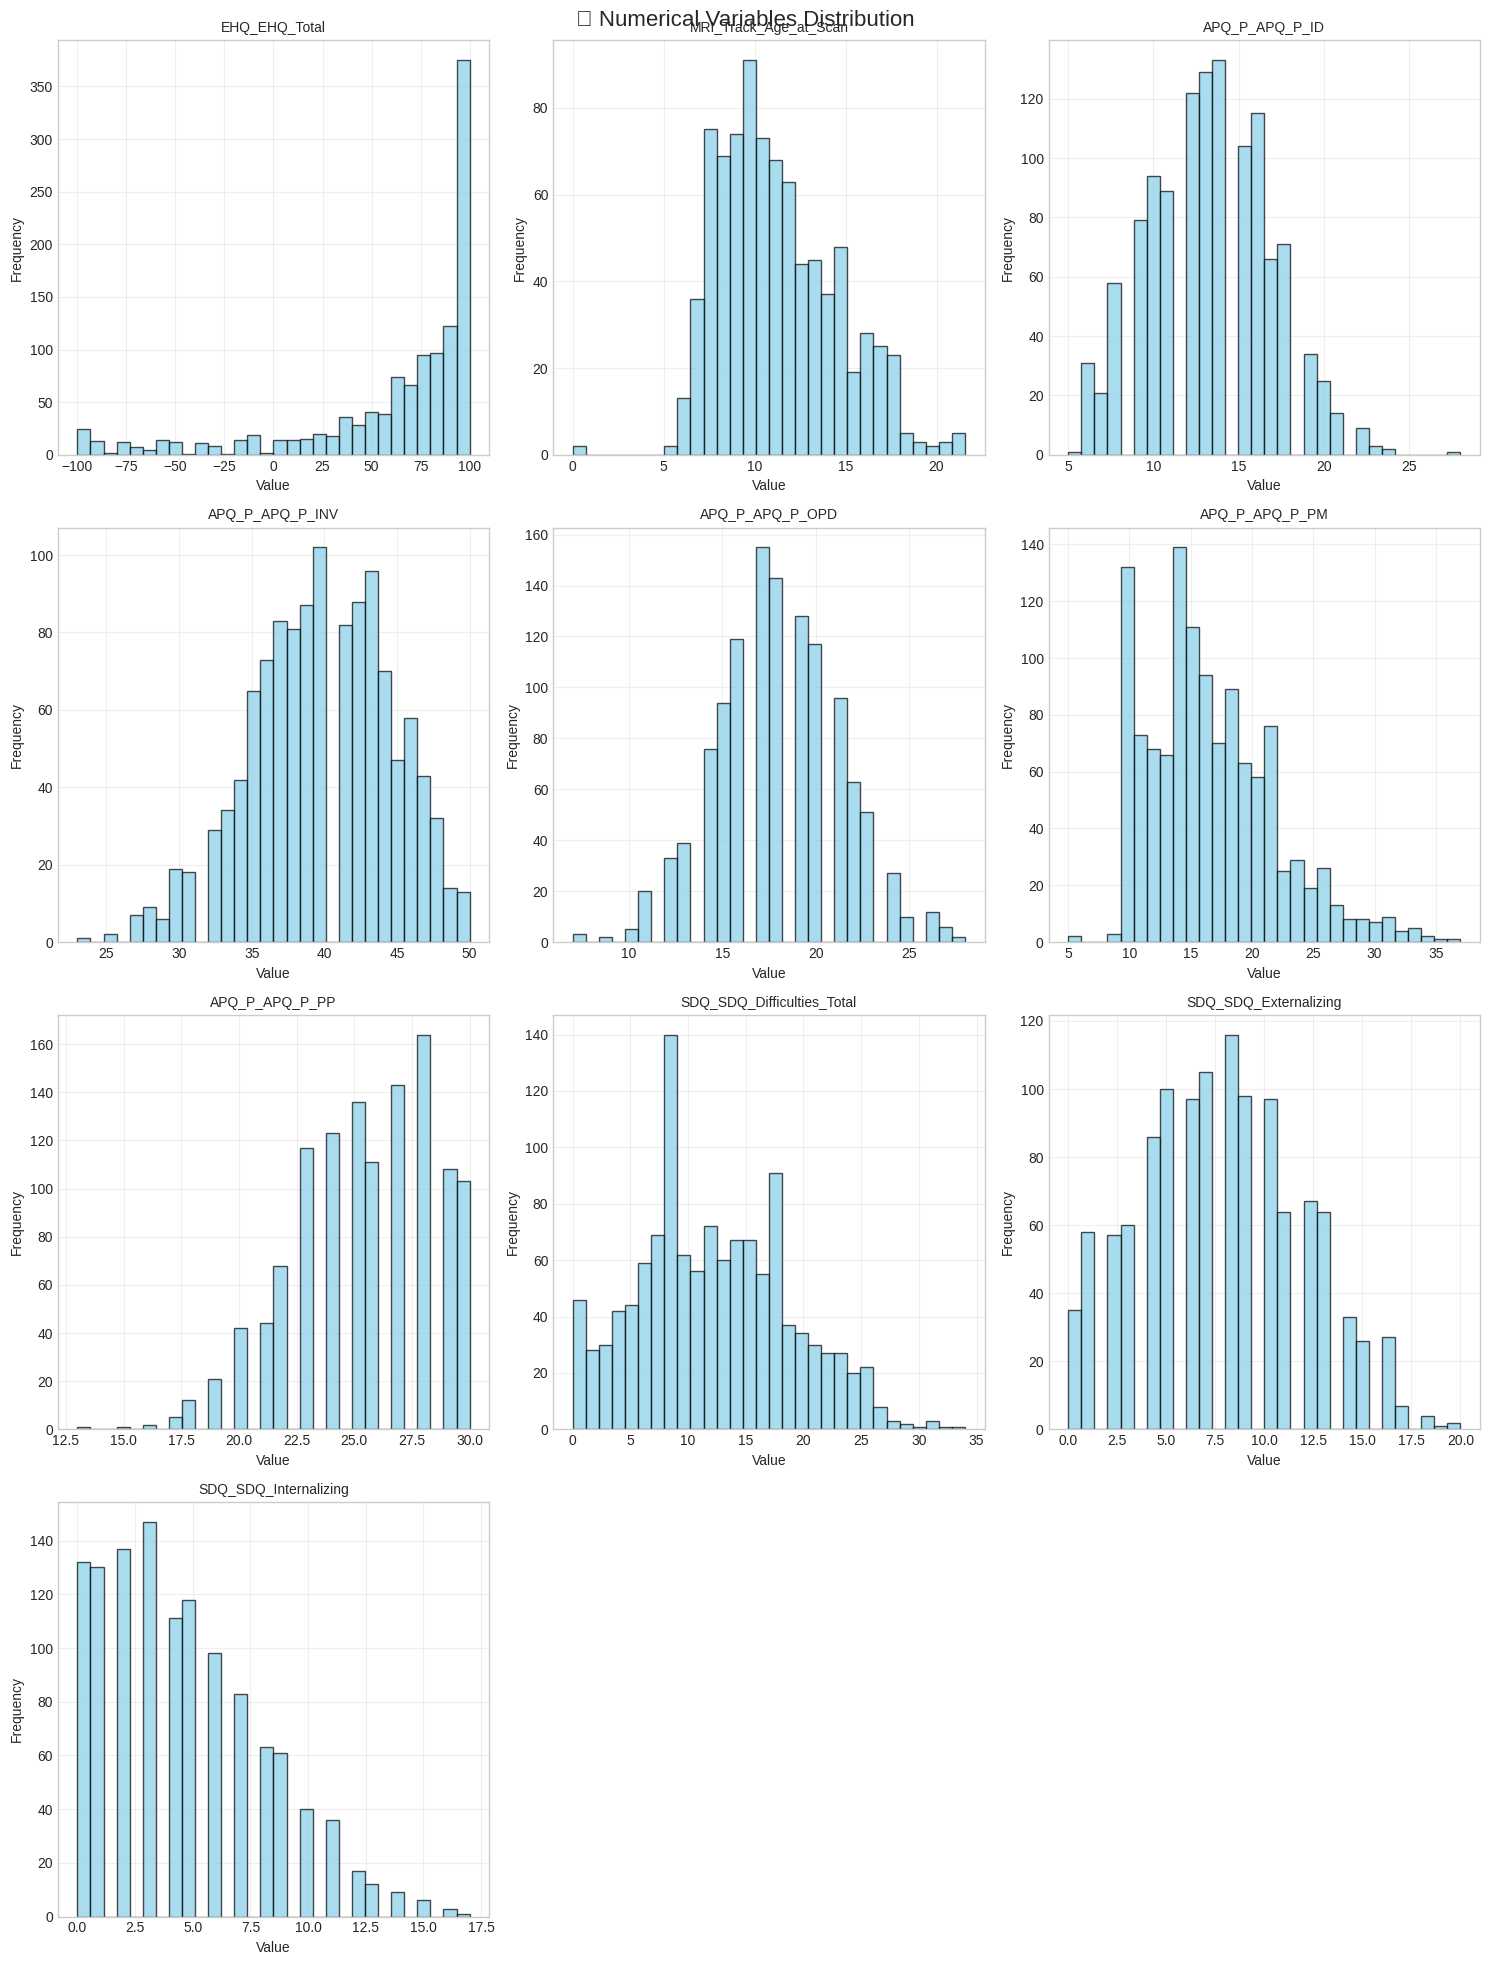

📊 Numerical Variables Summary:
       EHQ_EHQ_Total  MRI_Track_Age_at_Scan  APQ_P_APQ_P_ID  APQ_P_APQ_P_INV  \
count    1200.000000             853.000000     1201.000000      1201.000000   
mean       59.514750              11.245678       13.337219        39.767694   
std        49.744631               3.234372        3.593562         4.872729   
min      -100.000000               0.000000        5.000000        23.000000   
25%        46.670000               8.803901       11.000000        36.000000   
50%        77.800000              10.739219       13.000000        40.000000   
75%        94.470000              13.460871       16.000000        43.000000   
max       100.000000              21.564453       28.000000        50.000000   

       APQ_P_APQ_P_OPD  APQ_P_APQ_P_PM  APQ_P_APQ_P_PP  \
count      1201.000000     1201.000000     1201.000000   
mean         17.963364       16.557036       25.498751   
std           3.333965        5.146548        3.053720   
min           7.

In [8]:
def visualize_numerical_distributions(train_data, numerical_vars):
    """
    Create distribution plots for numerical variables using matplotlib/seaborn
    """
    n_vars = len(numerical_vars)
    n_cols = 3
    n_rows = (n_vars + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
    axes = axes.flatten() if n_rows > 1 else [axes] if n_rows == 1 else axes
    
    for i, var in enumerate(numerical_vars):
        if var in train_data.columns:
            data = train_data[var].dropna()
            axes[i].hist(data, bins=30, color='skyblue', alpha=0.7, edgecolor='black')
            axes[i].set_title(var, fontsize=10)
            axes[i].set_xlabel('Value')
            axes[i].set_ylabel('Frequency')
            axes[i].grid(alpha=0.3)
    
    # Hide empty subplots
    for i in range(len(numerical_vars), len(axes)):
        axes[i].set_visible(False)
    
    plt.suptitle('📊 Numerical Variables Distribution', fontsize=16)
    plt.tight_layout()
    plt.show()
    
    # Summary statistics
    print("📊 Numerical Variables Summary:")
    summary_stats = train_data[numerical_vars].describe()
    return summary_stats

# Visualize numerical distributions
if len(numerical_vars) > 0:
    summary_stats = visualize_numerical_distributions(train_data, numerical_vars)
    print(summary_stats)

<a id="preprocessing"></a>
# 🔧 Data Preprocessing

Now let's clean and prepare our data for machine learning.

In [9]:
def advanced_imputation(train_data, test_data, categorical_vars, numerical_vars, connectome_vars, seed=42):
    """
    Perform advanced imputation for different variable types
    """
    print("🔧 Starting Advanced Imputation...")
    
    # Make copies to avoid modifying original data
    train_processed = train_data.copy()
    test_processed = test_data.copy()
    
    # 1. Categorical Variables Imputation
    if categorical_vars:
        print("  📋 Imputing categorical variables...")
        cat_imputer = SimpleImputer(strategy='most_frequent')
        train_processed[categorical_vars] = cat_imputer.fit_transform(train_processed[categorical_vars])
        test_processed[categorical_vars] = cat_imputer.transform(test_processed[categorical_vars])
    
    # 2. Numerical Variables Imputation
    if numerical_vars:
        print("  📊 Imputing numerical variables...")
        num_imputer = IterativeImputer(
            estimator=LassoCV(random_state=seed), 
            max_iter=10,
            random_state=seed,
            initial_strategy='median'
        )
        train_processed[numerical_vars] = num_imputer.fit_transform(train_processed[numerical_vars])
        test_processed[numerical_vars] = num_imputer.transform(test_processed[numerical_vars])
    
    # 3. Connectome Variables Imputation
    if connectome_vars:
        print("  🧠 Imputing connectome variables...")
        connectome_missing = train_processed[connectome_vars].isnull().sum().sum()
        
        if connectome_missing > 0:
            connectome_imputer = KNNImputer(n_neighbors=5, weights='distance')
            train_processed[connectome_vars] = connectome_imputer.fit_transform(train_processed[connectome_vars])
            test_processed[connectome_vars] = connectome_imputer.transform(test_processed[connectome_vars])
            print(f"    🔄 Imputed {connectome_missing} missing values in connectome data")
    
    # Verification
    train_missing_after = train_processed.isnull().sum().sum()
    test_missing_after = test_processed.isnull().sum().sum()
    
    print(f"✅ Imputation Complete!")
    print(f"  📈 Training missing values remaining: {train_missing_after}")
    print(f"  📈 Test missing values remaining: {test_missing_after}")
    
    return train_processed, test_processed

# Perform imputation
train_clean, test_clean = advanced_imputation(
    train_data, test_data, categorical_vars, numerical_vars, connectome_vars, SEED
)

🔧 Starting Advanced Imputation...
  📋 Imputing categorical variables...
  📊 Imputing numerical variables...
  🧠 Imputing connectome variables...
✅ Imputation Complete!
  📈 Training missing values remaining: 0
  📈 Test missing values remaining: 0


🎯 Creating Balanced Datasets...
⚖️ Handling Class Imbalance for ADHD_Outcome
  📊 Before SMOTE: {1: 831, 0: 382}
  📊 After SMOTE: {1: 831, 0: 831}


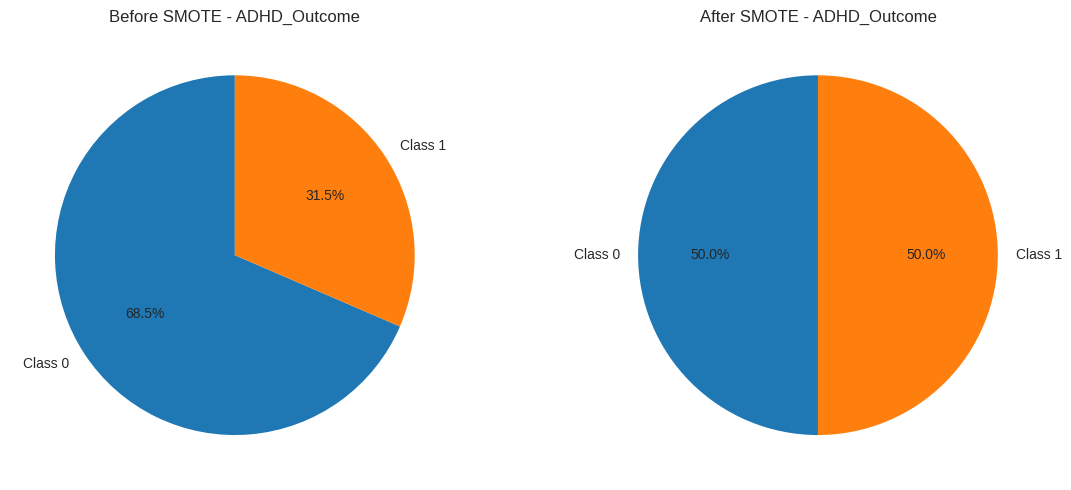

⚖️ Handling Class Imbalance for Sex_F
  📊 Before SMOTE: {0: 797, 1: 416}
  📊 After SMOTE: {0: 797, 1: 797}


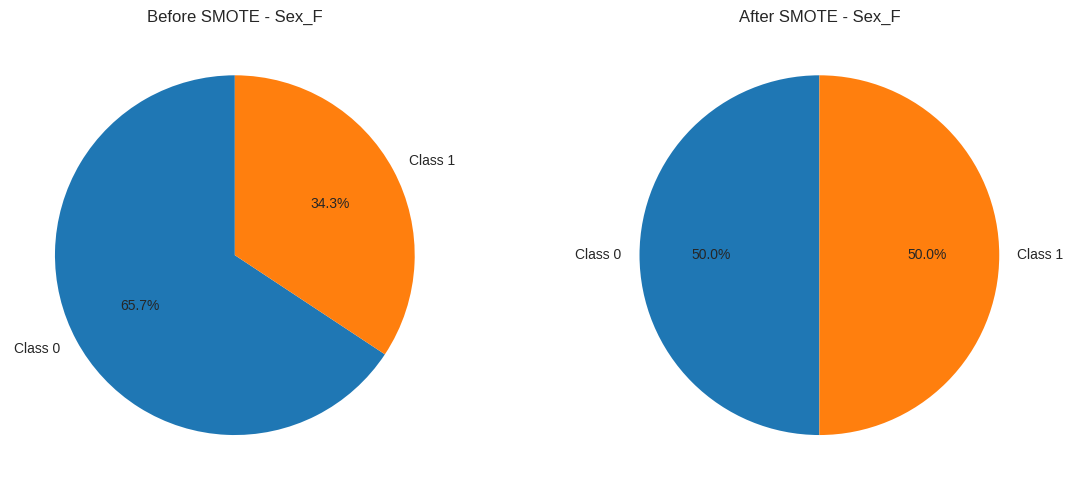

✅ Balanced datasets created successfully!


In [10]:
def handle_class_imbalance_with_visualization(train_data, target_col, seed=42):
    """
    Handle class imbalance using SMOTE with before/after visualization
    """
    print(f"⚖️ Handling Class Imbalance for {target_col}")
    
    # Separate features and target
    X = train_data.drop(columns=[target_col])
    y = train_data[target_col]
    
    print(f"  📊 Before SMOTE: {dict(Counter(y))}")
    
    # Apply SMOTE
    smote = SMOTE(sampling_strategy='auto', random_state=seed)
    X_resampled, y_resampled = smote.fit_resample(X, y)
    
    # Create resampled dataframe
    train_balanced = pd.DataFrame(X_resampled, columns=X.columns)
    train_balanced[target_col] = y_resampled
    
    # Generate new participant IDs
    def generate_participant_id(length=7):
        return ''.join(random.choices(string.ascii_uppercase, k=length))
    
    train_balanced['participant_id'] = [generate_participant_id() for _ in range(len(train_balanced))]
    
    print(f"  📊 After SMOTE: {dict(Counter(y_resampled))}")
    
    # Visualization
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    
    # Before SMOTE
    Counter(y).values()
    labels = ['Class 0', 'Class 1']
    ax1.pie(Counter(y).values(), labels=labels, autopct='%1.1f%%', startangle=90)
    ax1.set_title(f'Before SMOTE - {target_col}')
    
    # After SMOTE
    ax2.pie(Counter(y_resampled).values(), labels=labels, autopct='%1.1f%%', startangle=90)
    ax2.set_title(f'After SMOTE - {target_col}')
    
    plt.tight_layout()
    plt.show()
    
    return train_balanced

# Handle class imbalance for both targets
print("🎯 Creating Balanced Datasets...")

# ADHD balanced dataset
train_adhd_balanced = handle_class_imbalance_with_visualization(
    train_clean, 'ADHD_Outcome', SEED
)
train_adhd_balanced.drop('Sex_F', axis=1, inplace=True)

# Sex balanced dataset  
train_sex_balanced = handle_class_imbalance_with_visualization(
    train_clean, 'Sex_F', SEED
)
train_sex_balanced.drop('ADHD_Outcome', axis=1, inplace=True)

print("✅ Balanced datasets created successfully!")

<a id="feature-engineering"></a>
# ⚙️ Feature Engineering

Let's engineer features to improve model performance.

🔬 Applying PCA (Variance Retention: 0.95)
  📊 Original features: 19900
  📊 PCA components: 875
  📊 Variance explained: 0.950


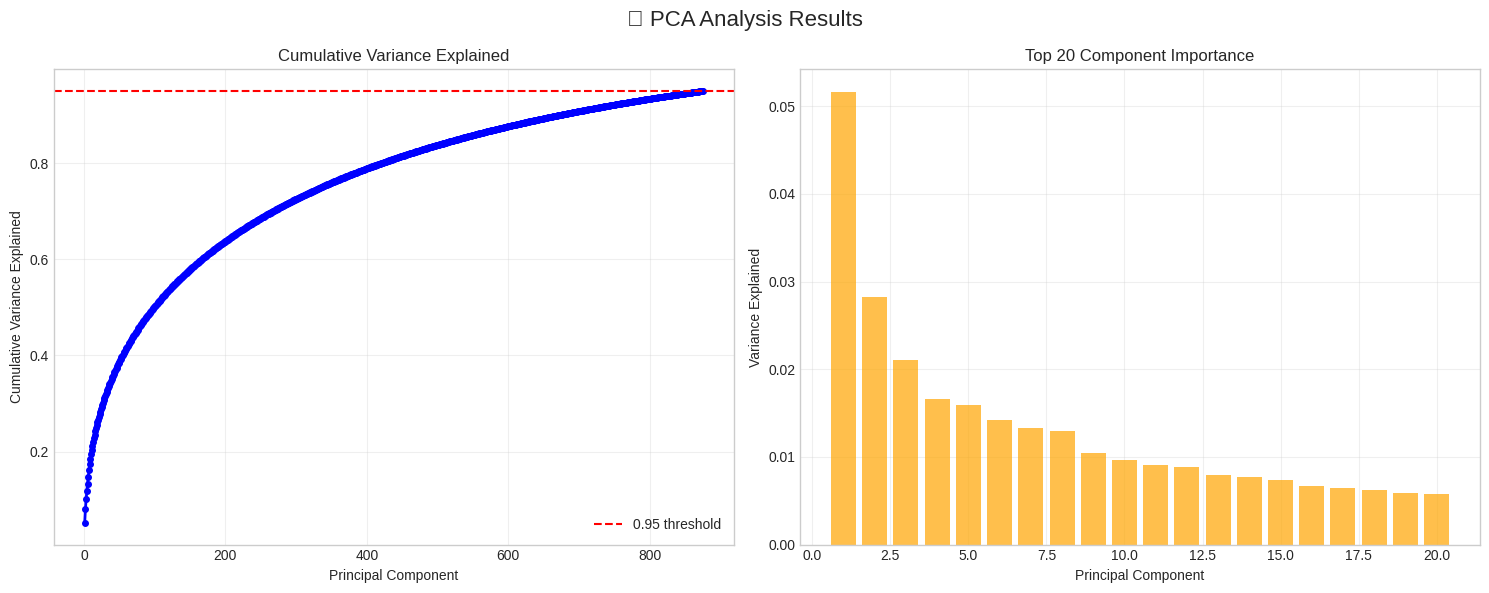

In [11]:
def apply_pca_with_visualization(train_adhd, train_sex, test_data, connectome_vars, variance_threshold=0.95):
    """
    Apply PCA with comprehensive visualization using matplotlib
    """
    print(f"🔬 Applying PCA (Variance Retention: {variance_threshold})")
    
    # Fit PCA
    pca = PCA(n_components=variance_threshold)
    train_adhd_pca = pca.fit_transform(train_adhd[connectome_vars])
    train_sex_pca = pca.transform(train_sex[connectome_vars])
    test_pca = pca.transform(test_data[connectome_vars])
    
    print(f"  📊 Original features: {len(connectome_vars)}")
    print(f"  📊 PCA components: {train_adhd_pca.shape[1]}")
    print(f"  📊 Variance explained: {pca.explained_variance_ratio_.sum():.3f}")
    
    # Visualization
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    
    # Cumulative variance plot
    cumvar = np.cumsum(pca.explained_variance_ratio_)
    axes[0].plot(range(1, len(cumvar) + 1), cumvar, 'bo-', linewidth=2, markersize=4)
    axes[0].axhline(y=variance_threshold, color='red', linestyle='--', 
                    label=f'{variance_threshold} threshold')
    axes[0].set_xlabel('Principal Component')
    axes[0].set_ylabel('Cumulative Variance Explained')
    axes[0].set_title('Cumulative Variance Explained')
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()
    
    # Component importance
    n_components_to_show = min(20, len(pca.explained_variance_ratio_))
    axes[1].bar(range(1, n_components_to_show + 1), 
                pca.explained_variance_ratio_[:n_components_to_show], 
                color='orange', alpha=0.7)
    axes[1].set_xlabel('Principal Component')
    axes[1].set_ylabel('Variance Explained')
    axes[1].set_title('Top 20 Component Importance')
    axes[1].grid(True, alpha=0.3)
    
    plt.suptitle('🔬 PCA Analysis Results', fontsize=16)
    plt.tight_layout()
    plt.show()
    
    # Convert to DataFrames
    pca_columns = [f'PCA_{i+1}' for i in range(train_adhd_pca.shape[1])]
    
    train_adhd_pca_df = pd.DataFrame(train_adhd_pca, columns=pca_columns)
    train_sex_pca_df = pd.DataFrame(train_sex_pca, columns=pca_columns)
    test_pca_df = pd.DataFrame(test_pca, columns=pca_columns)
    
    return train_adhd_pca_df, train_sex_pca_df, test_pca_df, pca

# Apply PCA
train_adhd_pca_df, train_sex_pca_df, test_pca_df, pca_model = apply_pca_with_visualization(
    train_adhd_balanced, train_sex_balanced, test_clean, connectome_vars, PCA_VARIANCE_THRESHOLD
)

🎯 Performing Feature Selection...
  📊 Applying variance threshold...
    ✅ Selected 10 out of 10 numerical features
  🔄 Applying Recursive Feature Elimination...
    ✅ RFECV selected 8 optimal features


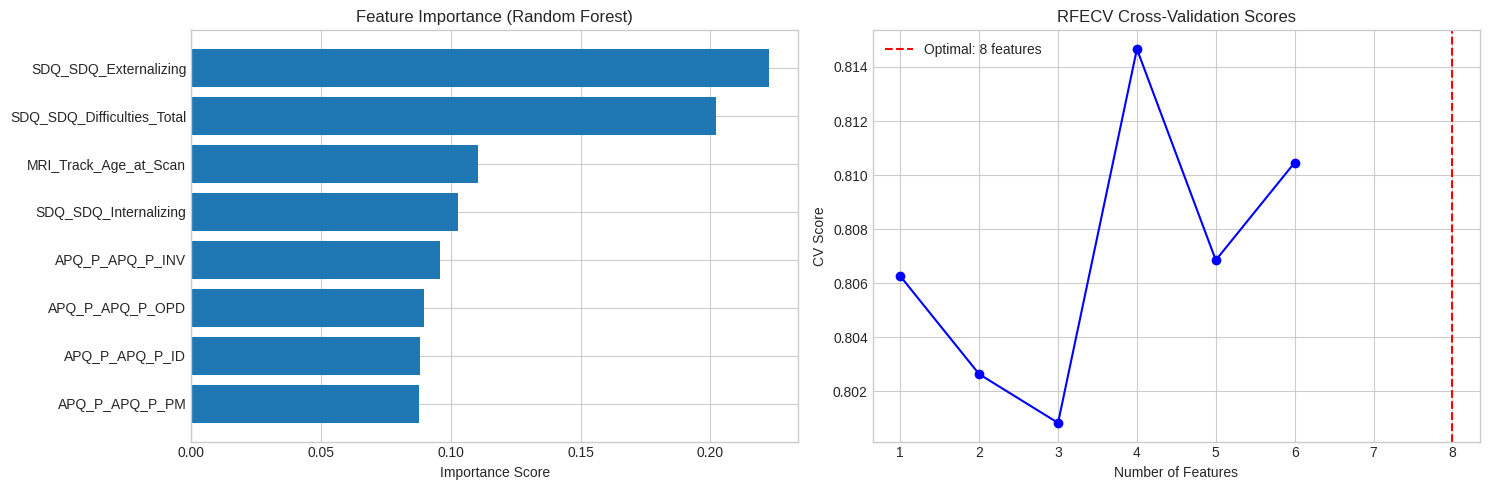

In [12]:
def feature_selection_with_visualization(train_adhd, train_sex, test_data, numerical_vars, target_col='ADHD_Outcome'):
    """
    Perform feature selection with visualization
    """
    print("🎯 Performing Feature Selection...")
    
    # Variance threshold filtering
    print("  📊 Applying variance threshold...")
    selector = VarianceThreshold(threshold=VARIANCE_THRESHOLD)
    
    # Fit on ADHD data
    selected_features_adhd = selector.fit_transform(train_adhd[numerical_vars])
    selected_feature_names = train_adhd[numerical_vars].columns[selector.get_support()]
    
    print(f"    ✅ Selected {len(selected_feature_names)} out of {len(numerical_vars)} numerical features")
    
    # Apply to all datasets
    train_adhd_selected = pd.DataFrame(selected_features_adhd, columns=selected_feature_names)
    train_sex_selected = pd.DataFrame(selector.transform(train_sex[numerical_vars]), columns=selected_feature_names)
    test_selected = pd.DataFrame(selector.transform(test_data[numerical_vars]), columns=selected_feature_names)
    
    # RFECV for recursive feature elimination
    print("  🔄 Applying Recursive Feature Elimination...")
    if len(selected_feature_names) > 5:  # Only if we have enough features
        rf = RandomForestClassifier(random_state=SEED)
        rfecv = RFECV(
            estimator=rf, 
            step=1, 
            cv=StratifiedKFold(5, shuffle=True, random_state=SEED), 
            scoring='accuracy', 
            min_features_to_select=5
        )
        
        y_adhd = train_adhd[target_col]
        rfecv.fit(train_adhd_selected, y_adhd)
        optimal_features = selected_feature_names[rfecv.support_]
        
        print(f"    ✅ RFECV selected {len(optimal_features)} optimal features")
        
        # Apply optimal feature selection
        train_adhd_selected = train_adhd_selected[optimal_features]
        train_sex_selected = train_sex_selected[optimal_features]
        test_selected = test_selected[optimal_features]
        
        # Visualization of feature selection
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
        
        # Feature importance from Random Forest
        rf.fit(train_adhd_selected, y_adhd)
        feature_importance = pd.DataFrame({
            'feature': optimal_features,
            'importance': rf.feature_importances_
        }).sort_values('importance', ascending=True)
        
        ax1.barh(feature_importance['feature'], feature_importance['importance'])
        ax1.set_title('Feature Importance (Random Forest)')
        ax1.set_xlabel('Importance Score')
        
        # RFECV scores
        ax2.plot(range(1, len(rfecv.cv_results_['mean_test_score']) + 1), 
                rfecv.cv_results_['mean_test_score'], 'bo-')
        ax2.axvline(x=rfecv.n_features_, color='red', linestyle='--', 
                   label=f'Optimal: {rfecv.n_features_} features')
        ax2.set_title('RFECV Cross-Validation Scores')
        ax2.set_xlabel('Number of Features')
        ax2.set_ylabel('CV Score')
        ax2.legend()
        
        plt.tight_layout()
        plt.show()
        
        return train_adhd_selected, train_sex_selected, test_selected, optimal_features
    else:
        return train_adhd_selected, train_sex_selected, test_selected, selected_feature_names

# Perform feature selection
train_adhd_features, train_sex_features, test_features, selected_features = feature_selection_with_visualization(
    train_adhd_balanced, train_sex_balanced, test_clean, numerical_vars
)

In [13]:
def combine_engineered_features(adhd_features, sex_features, test_features, 
                              adhd_pca, sex_pca, test_pca,
                              adhd_data, sex_data, test_data, categorical_vars):
    """
    Combine all engineered features into final datasets
    """
    print("🔗 Combining All Engineered Features...")
    
    # Combine features for ADHD model
    train_final_adhd = pd.concat([
        adhd_features,
        adhd_pca,
        adhd_data[['participant_id', 'ADHD_Outcome']],
        adhd_data[categorical_vars]
    ], axis=1)
    
    # Combine features for Sex model
    train_final_sex = pd.concat([
        sex_features,
        sex_pca,
        sex_data[['participant_id', 'Sex_F']],
        sex_data[categorical_vars]
    ], axis=1)
    
    # Combine features for test data
    test_final = pd.concat([
        test_features,
        test_pca,
        test_data.reset_index()[['participant_id']],
        test_data.reset_index()[categorical_vars]
    ], axis=1)
    
    # Remove duplicate columns
    train_final_adhd = train_final_adhd.loc[:, ~train_final_adhd.columns.duplicated()]
    train_final_sex = train_final_sex.loc[:, ~train_final_sex.columns.duplicated()]
    test_final = test_final.loc[:, ~test_final.columns.duplicated()]
    
    # Set participant_id as index
    train_final_adhd.set_index('participant_id', inplace=True)
    train_final_sex.set_index('participant_id', inplace=True)
    test_final.set_index('participant_id', inplace=True)
    
    print(f"✅ Final dataset shapes:")
    print(f"  📊 ADHD training: {train_final_adhd.shape}")
    print(f"  📊 Sex training: {train_final_sex.shape}")
    print(f"  📊 Test: {test_final.shape}")
    
    return train_final_adhd, train_final_sex, test_final

# Combine all features
train_final_adhd, train_final_sex, test_final = combine_engineered_features(
    train_adhd_features, train_sex_features, test_features,
    train_adhd_pca_df, train_sex_pca_df, test_pca_df,
    train_adhd_balanced, train_sex_balanced, test_clean,
    categorical_vars
)

🔗 Combining All Engineered Features...
✅ Final dataset shapes:
  📊 ADHD training: (1662, 901)
  📊 Sex training: (1594, 901)
  📊 Test: (304, 900)


<a id="modeling"></a>
# 🤖 Model Training & Evaluation

Now let's train our models and optimize thresholds.

In [14]:
def prepare_model_data(train_adhd, train_sex, test_final):
    """
    Prepare data for model training
    """
    print("📋 Preparing Model Data...")
    
    # ADHD model data
    X_train_adhd = train_adhd.drop('ADHD_Outcome', axis=1)
    y_train_adhd = train_adhd['ADHD_Outcome']
    X_test_adhd = test_final[X_train_adhd.columns]
    
    # Sex model data
    X_train_sex = train_sex.drop('Sex_F', axis=1)
    y_train_sex = train_sex['Sex_F']
    X_test_sex = test_final[X_train_sex.columns]
    
    print(f"✅ Data prepared:")
    print(f"  📊 ADHD features: {X_train_adhd.shape[1]}")
    print(f"  📊 Sex features: {X_train_sex.shape[1]}")
    
    return X_train_adhd, y_train_adhd, X_test_adhd, X_train_sex, y_train_sex, X_test_sex

# Prepare model data
X_train_adhd, y_train_adhd, X_test_adhd, X_train_sex, y_train_sex, X_test_sex = prepare_model_data(
    train_final_adhd, train_final_sex, test_final
)

📋 Preparing Model Data...
✅ Data prepared:
  📊 ADHD features: 900
  📊 Sex features: 900


🎯 Optimizing Threshold for ADHD Model...


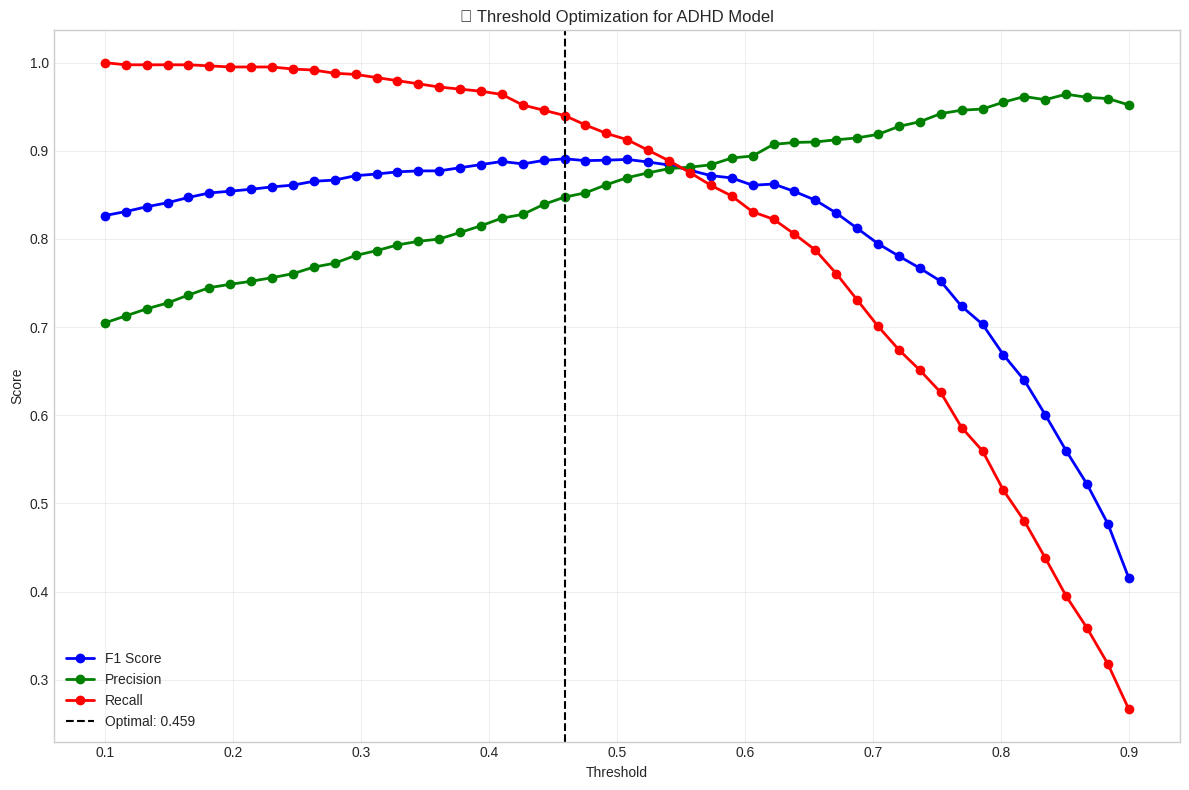

  ✅ Optimal threshold: 0.4592
  📊 Best F1 score: 0.8910
🎯 Optimizing Threshold for Sex Model...


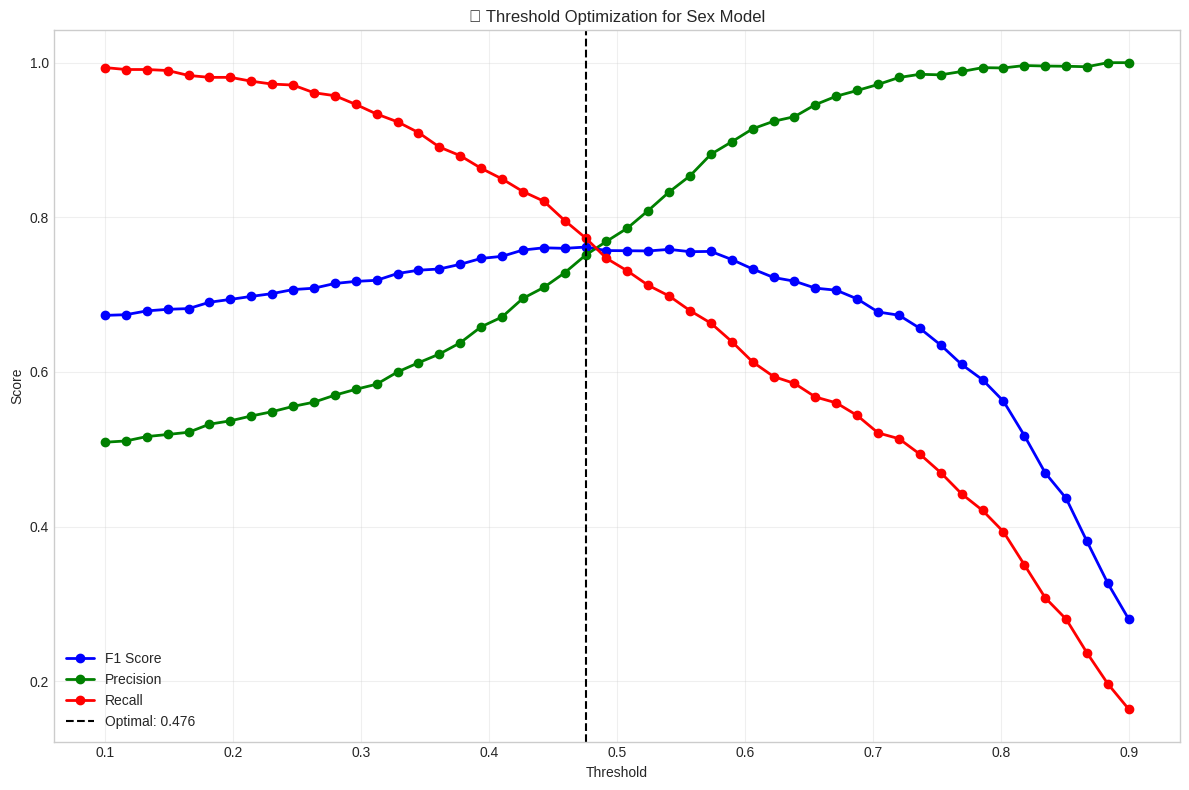

  ✅ Optimal threshold: 0.4755
  📊 Best F1 score: 0.7615


In [15]:
def optimize_threshold_with_visualization(X, y, model_params, model_name, n_folds=5):
    """
    Find optimal threshold with comprehensive visualization using matplotlib
    """
    print(f"🎯 Optimizing Threshold for {model_name}...")
    
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=SEED)
    thresholds = np.linspace(0.1, 0.9, 50)
    
    threshold_scores = []
    all_f1_scores = []
    all_precision_scores = []
    all_recall_scores = []
    
    for threshold in thresholds:
        fold_f1_scores = []
        fold_precision_scores = []
        fold_recall_scores = []
        
        for train_idx, val_idx in kf.split(X):
            X_fold_train, X_fold_val = X.iloc[train_idx], X.iloc[val_idx]
            y_fold_train, y_fold_val = y.iloc[train_idx], y.iloc[val_idx]
            
            # Train model
            model = xgb.XGBRegressor(**model_params)
            model.fit(X_fold_train, y_fold_train)
            
            # Predict and evaluate
            y_pred_proba = model.predict(X_fold_val)
            y_pred = (y_pred_proba >= threshold).astype(int)
            
            fold_f1 = f1_score(y_fold_val, y_pred, zero_division=0)
            fold_precision = precision_score(y_fold_val, y_pred, zero_division=0)
            fold_recall = recall_score(y_fold_val, y_pred, zero_division=0)
            
            fold_f1_scores.append(fold_f1)
            fold_precision_scores.append(fold_precision)
            fold_recall_scores.append(fold_recall)
        
        mean_f1 = np.mean(fold_f1_scores)
        mean_precision = np.mean(fold_precision_scores)
        mean_recall = np.mean(fold_recall_scores)
        
        threshold_scores.append((threshold, mean_f1))
        all_f1_scores.append(mean_f1)
        all_precision_scores.append(mean_precision)
        all_recall_scores.append(mean_recall)
    
    # Find optimal threshold
    optimal_threshold, best_f1 = max(threshold_scores, key=lambda x: x[1])
    
    # Visualization
    plt.figure(figsize=(12, 8))
    
    plt.plot(thresholds, all_f1_scores, 'bo-', linewidth=2, label='F1 Score')
    plt.plot(thresholds, all_precision_scores, 'go-', linewidth=2, label='Precision')
    plt.plot(thresholds, all_recall_scores, 'ro-', linewidth=2, label='Recall')
    
    plt.axvline(x=optimal_threshold, color='black', linestyle='--', 
                label=f'Optimal: {optimal_threshold:.3f}')
    
    plt.xlabel('Threshold')
    plt.ylabel('Score')
    plt.title(f'🎯 Threshold Optimization for {model_name}')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    print(f"  ✅ Optimal threshold: {optimal_threshold:.4f}")
    print(f"  📊 Best F1 score: {best_f1:.4f}")
    
    return optimal_threshold

# Model parameters
params_adhd = {
    'learning_rate': 0.07053905004210037, 
    'max_depth': 9, 
    'n_estimators': 224,
    'min_child_weight': 2, 
    'gamma': 5.502839383685882e-06,
    'subsample': 0.569342857980725, 
    'colsample_bytree': 0.8264368132501649, 
    'reg_alpha': 6.081064742359052e-06,
    'reg_lambda': 8.582461895577443e-05,
    'random_state': SEED,
    'eval_metric': 'rmse'
}

params_sex = {
    'colsample_bytree': 0.8,
    'learning_rate': 0.050000002,
    'max_depth': 3,
    'n_estimators': 284,
    'subsample': 0.9,
    'objective': 'reg:squarederror',
    'random_state': SEED
}

# Optimize thresholds
adhd_threshold = optimize_threshold_with_visualization(X_train_adhd, y_train_adhd, params_adhd, "ADHD Model")
sex_threshold = optimize_threshold_with_visualization(X_train_sex, y_train_sex, params_sex, "Sex Model")

🚀 Training Final Models...
  🧠 Training ADHD model...
  ⚧️ Training Sex model...
📊 Evaluating models with cross-validation...


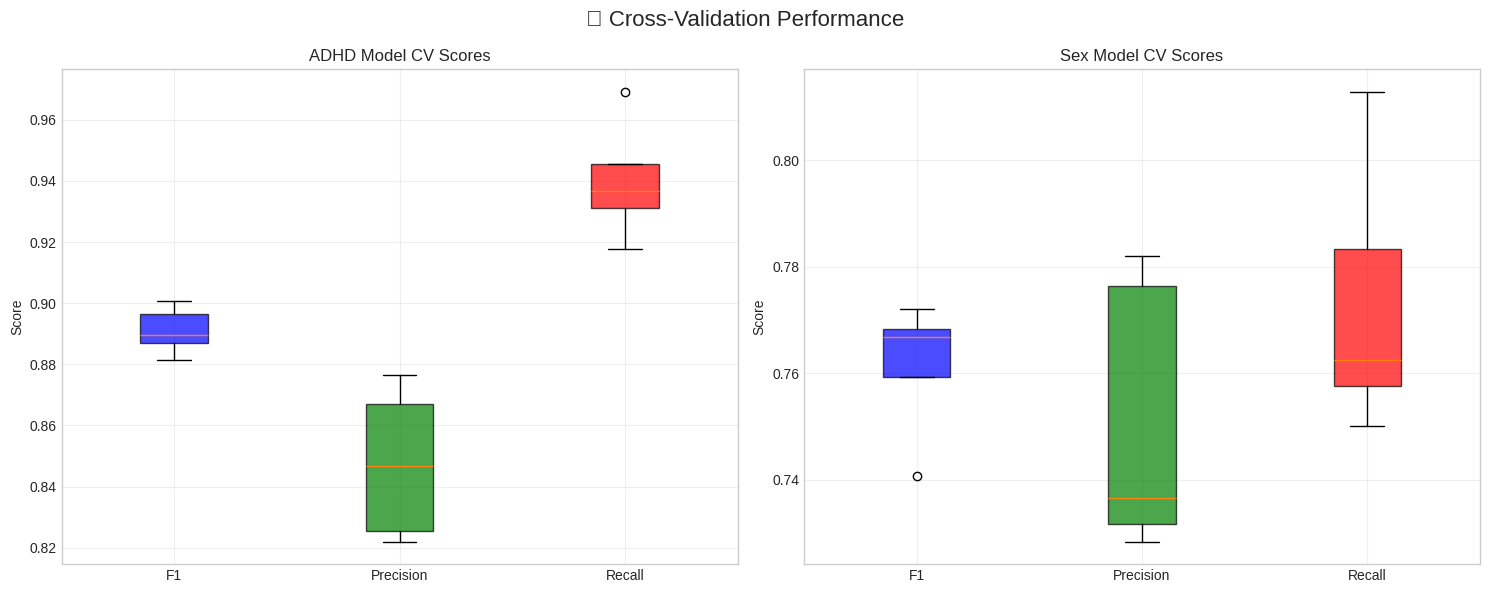


📈 Cross-Validation Results:
ADHD Model:
  F1: 0.8910 ± 0.0068
  Precision: 0.8475 ± 0.0217
  Recall: 0.9401 ± 0.0171

Sex Model:
  F1: 0.7615 ± 0.0112
  Precision: 0.7510 ± 0.0233
  Recall: 0.7733 ± 0.0227


In [16]:
def train_final_models_with_evaluation(X_train_adhd, y_train_adhd, X_train_sex, y_train_sex, 
                                     params_adhd, params_sex, adhd_threshold, sex_threshold):
    """
    Train final models and evaluate performance using matplotlib
    """
    print("🚀 Training Final Models...")
    
    # Train ADHD model
    print("  🧠 Training ADHD model...")
    model_adhd = xgb.XGBRegressor(**params_adhd)
    model_adhd.fit(X_train_adhd, y_train_adhd)
    
    # Train Sex model
    print("  ⚧️ Training Sex model...")
    model_sex = xgb.XGBRegressor(**params_sex)
    model_sex.fit(X_train_sex, y_train_sex)
    
    # Cross-validation evaluation
    print("📊 Evaluating models with cross-validation...")
    
    def evaluate_model_cv(X, y, model_params, threshold, model_name):
        kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
        cv_scores = {'f1': [], 'precision': [], 'recall': []}
        
        for train_idx, val_idx in kf.split(X):
            X_fold_train, X_fold_val = X.iloc[train_idx], X.iloc[val_idx]
            y_fold_train, y_fold_val = y.iloc[train_idx], y.iloc[val_idx]
            
            model = xgb.XGBRegressor(**model_params)
            model.fit(X_fold_train, y_fold_train)
            
            y_pred_proba = model.predict(X_fold_val)
            y_pred = (y_pred_proba >= threshold).astype(int)
            
            cv_scores['f1'].append(f1_score(y_fold_val, y_pred, zero_division=0))
            cv_scores['precision'].append(precision_score(y_fold_val, y_pred, zero_division=0))
            cv_scores['recall'].append(recall_score(y_fold_val, y_pred, zero_division=0))
        
        return cv_scores
    
    # Evaluate both models
    adhd_cv_scores = evaluate_model_cv(X_train_adhd, y_train_adhd, params_adhd, adhd_threshold, "ADHD")
    sex_cv_scores = evaluate_model_cv(X_train_sex, y_train_sex, params_sex, sex_threshold, "Sex")
    
    # Visualization of CV results
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    
    metrics = ['f1', 'precision', 'recall']
    colors = ['blue', 'green', 'red']
    
    # ADHD model CV scores
    box_data_adhd = [adhd_cv_scores[metric] for metric in metrics]
    bp1 = axes[0].boxplot(box_data_adhd, labels=[m.title() for m in metrics], patch_artist=True)
    for patch, color in zip(bp1['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    axes[0].set_title('ADHD Model CV Scores')
    axes[0].set_ylabel('Score')
    axes[0].grid(True, alpha=0.3)
    
    # Sex model CV scores
    box_data_sex = [sex_cv_scores[metric] for metric in metrics]
    bp2 = axes[1].boxplot(box_data_sex, labels=[m.title() for m in metrics], patch_artist=True)
    for patch, color in zip(bp2['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    axes[1].set_title('Sex Model CV Scores')
    axes[1].set_ylabel('Score')
    axes[1].grid(True, alpha=0.3)
    
    plt.suptitle('📊 Cross-Validation Performance', fontsize=16)
    plt.tight_layout()
    plt.show()
    
    # Print CV results
    print("\n📈 Cross-Validation Results:")
    print("ADHD Model:")
    for metric in metrics:
        mean_score = np.mean(adhd_cv_scores[metric])
        std_score = np.std(adhd_cv_scores[metric])
        print(f"  {metric.title()}: {mean_score:.4f} ± {std_score:.4f}")
    
    print("\nSex Model:")
    for metric in metrics:
        mean_score = np.mean(sex_cv_scores[metric])
        std_score = np.std(sex_cv_scores[metric])
        print(f"  {metric.title()}: {mean_score:.4f} ± {std_score:.4f}")
    
    return model_adhd, model_sex

# Train final models
model_adhd, model_sex = train_final_models_with_evaluation(
    X_train_adhd, y_train_adhd, X_train_sex, y_train_sex,
    params_adhd, params_sex, adhd_threshold, sex_threshold
)

<a id="results"></a>
# 📊 Results & Visualizations

Let's analyze our model results and create predictions.

🔮 Making Final Predictions...
📊 Prediction Analysis:
  ADHD Predictions: {1: 205, 0: 99}
  Sex Predictions: {1: 181, 0: 123}


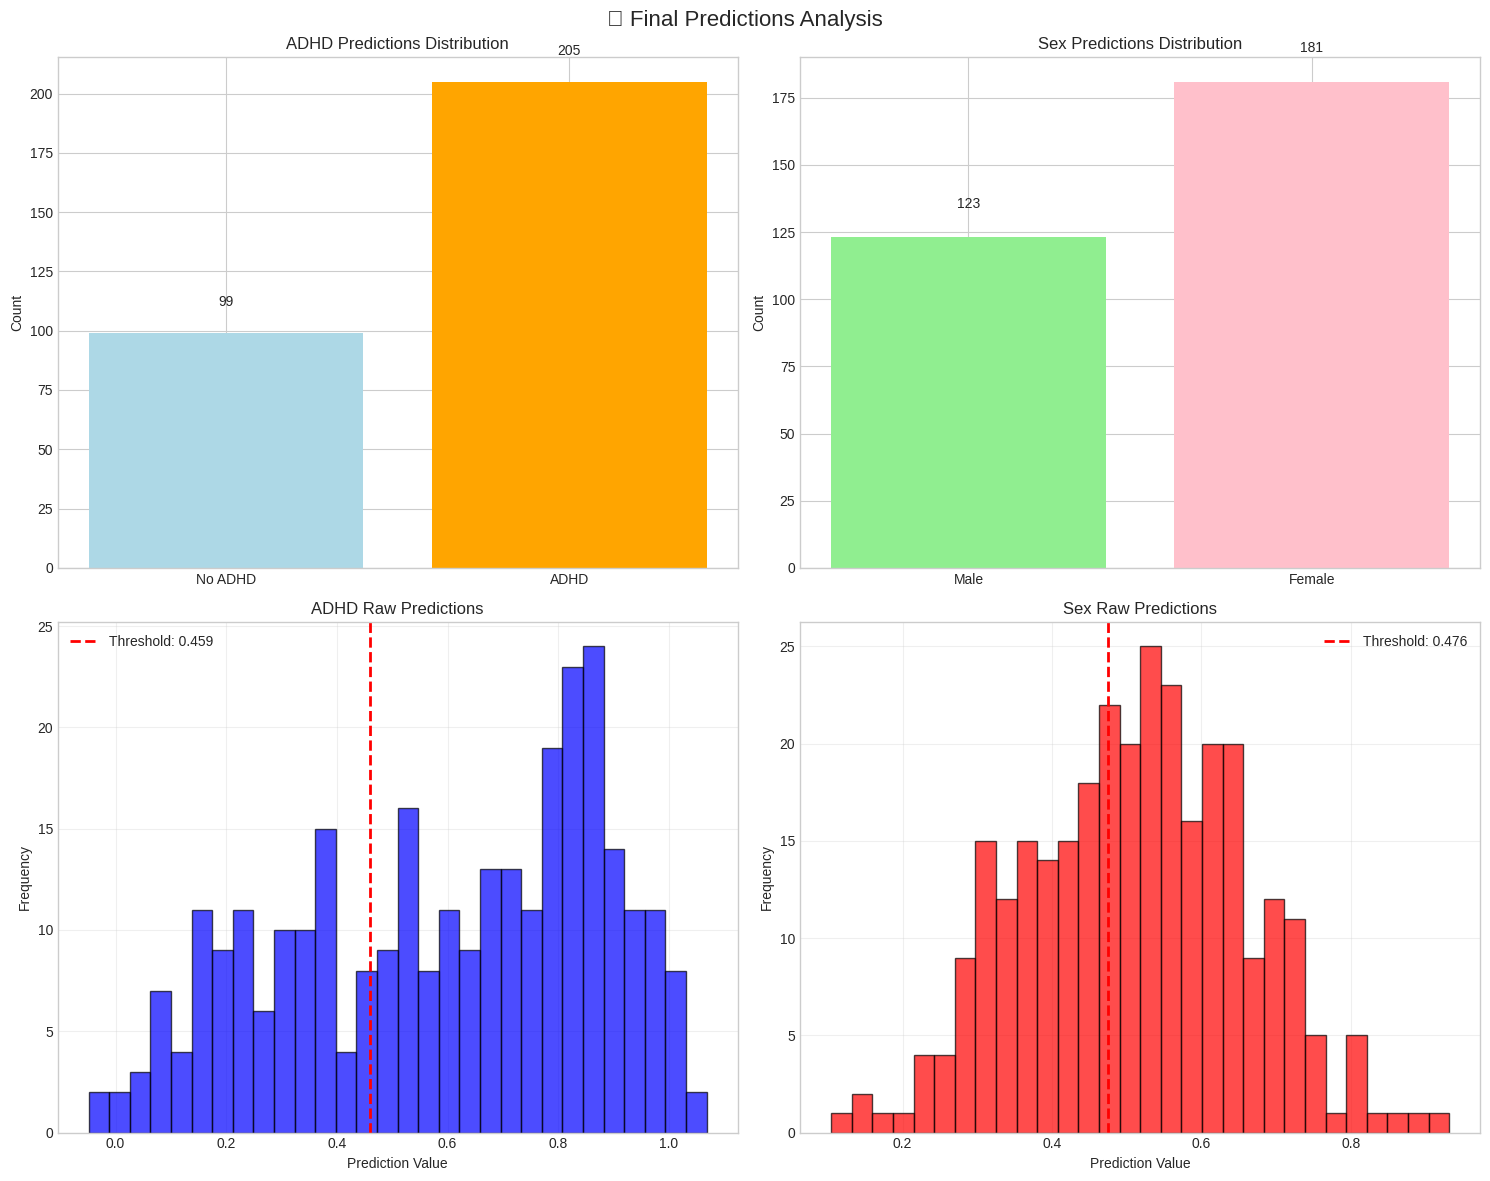

In [17]:
def make_predictions_with_analysis(model_adhd, model_sex, X_test_adhd, X_test_sex, 
                                 adhd_threshold, sex_threshold, test_final):
    """
    Make predictions and analyze results using matplotlib
    """
    print("🔮 Making Final Predictions...")
    
    # Make predictions
    adhd_preds_raw = model_adhd.predict(X_test_adhd)
    sex_preds_raw = model_sex.predict(X_test_sex)
    
    # Apply thresholds
    adhd_preds = (adhd_preds_raw >= adhd_threshold).astype(int)
    sex_preds = (sex_preds_raw >= sex_threshold).astype(int)
    
    # Create submission dataframe
    submission = pd.DataFrame({
        'participant_id': test_final.index,
        'ADHD_Outcome': adhd_preds,
        'Sex_F': sex_preds,
    })
    
    # Analysis and visualization
    print("📊 Prediction Analysis:")
    print(f"  ADHD Predictions: {dict(Counter(adhd_preds))}")
    print(f"  Sex Predictions: {dict(Counter(sex_preds))}")
    
    # Visualization
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    
    # ADHD predictions distribution
    adhd_counts = Counter(adhd_preds)
    axes[0, 0].bar(['No ADHD', 'ADHD'], [adhd_counts[0], adhd_counts[1]], 
                   color=['lightblue', 'orange'])
    axes[0, 0].set_title('ADHD Predictions Distribution')
    axes[0, 0].set_ylabel('Count')
    for i, v in enumerate([adhd_counts[0], adhd_counts[1]]):
        axes[0, 0].text(i, v + 10, str(v), ha='center', va='bottom')
    
    # Sex predictions distribution
    sex_counts = Counter(sex_preds)
    axes[0, 1].bar(['Male', 'Female'], [sex_counts[0], sex_counts[1]], 
                   color=['lightgreen', 'pink'])
    axes[0, 1].set_title('Sex Predictions Distribution')
    axes[0, 1].set_ylabel('Count')
    for i, v in enumerate([sex_counts[0], sex_counts[1]]):
        axes[0, 1].text(i, v + 10, str(v), ha='center', va='bottom')
    
    # Raw predictions histograms
    axes[1, 0].hist(adhd_preds_raw, bins=30, color='blue', alpha=0.7, edgecolor='black')
    axes[1, 0].axvline(x=adhd_threshold, color='red', linestyle='--', linewidth=2, 
                       label=f'Threshold: {adhd_threshold:.3f}')
    axes[1, 0].set_title('ADHD Raw Predictions')
    axes[1, 0].set_xlabel('Prediction Value')
    axes[1, 0].set_ylabel('Frequency')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    
    axes[1, 1].hist(sex_preds_raw, bins=30, color='red', alpha=0.7, edgecolor='black')
    axes[1, 1].axvline(x=sex_threshold, color='red', linestyle='--', linewidth=2,
                       label=f'Threshold: {sex_threshold:.3f}')
    axes[1, 1].set_title('Sex Raw Predictions')
    axes[1, 1].set_xlabel('Prediction Value')
    axes[1, 1].set_ylabel('Frequency')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.suptitle('🔮 Final Predictions Analysis', fontsize=16)
    plt.tight_layout()
    plt.show()
    
    return submission, adhd_preds_raw, sex_preds_raw

# Make final predictions
submission, adhd_raw_preds, sex_raw_preds = make_predictions_with_analysis(
    model_adhd, model_sex, X_test_adhd, X_test_sex,
    adhd_threshold, sex_threshold, test_final
)

🔍 Analyzing Feature Importance...


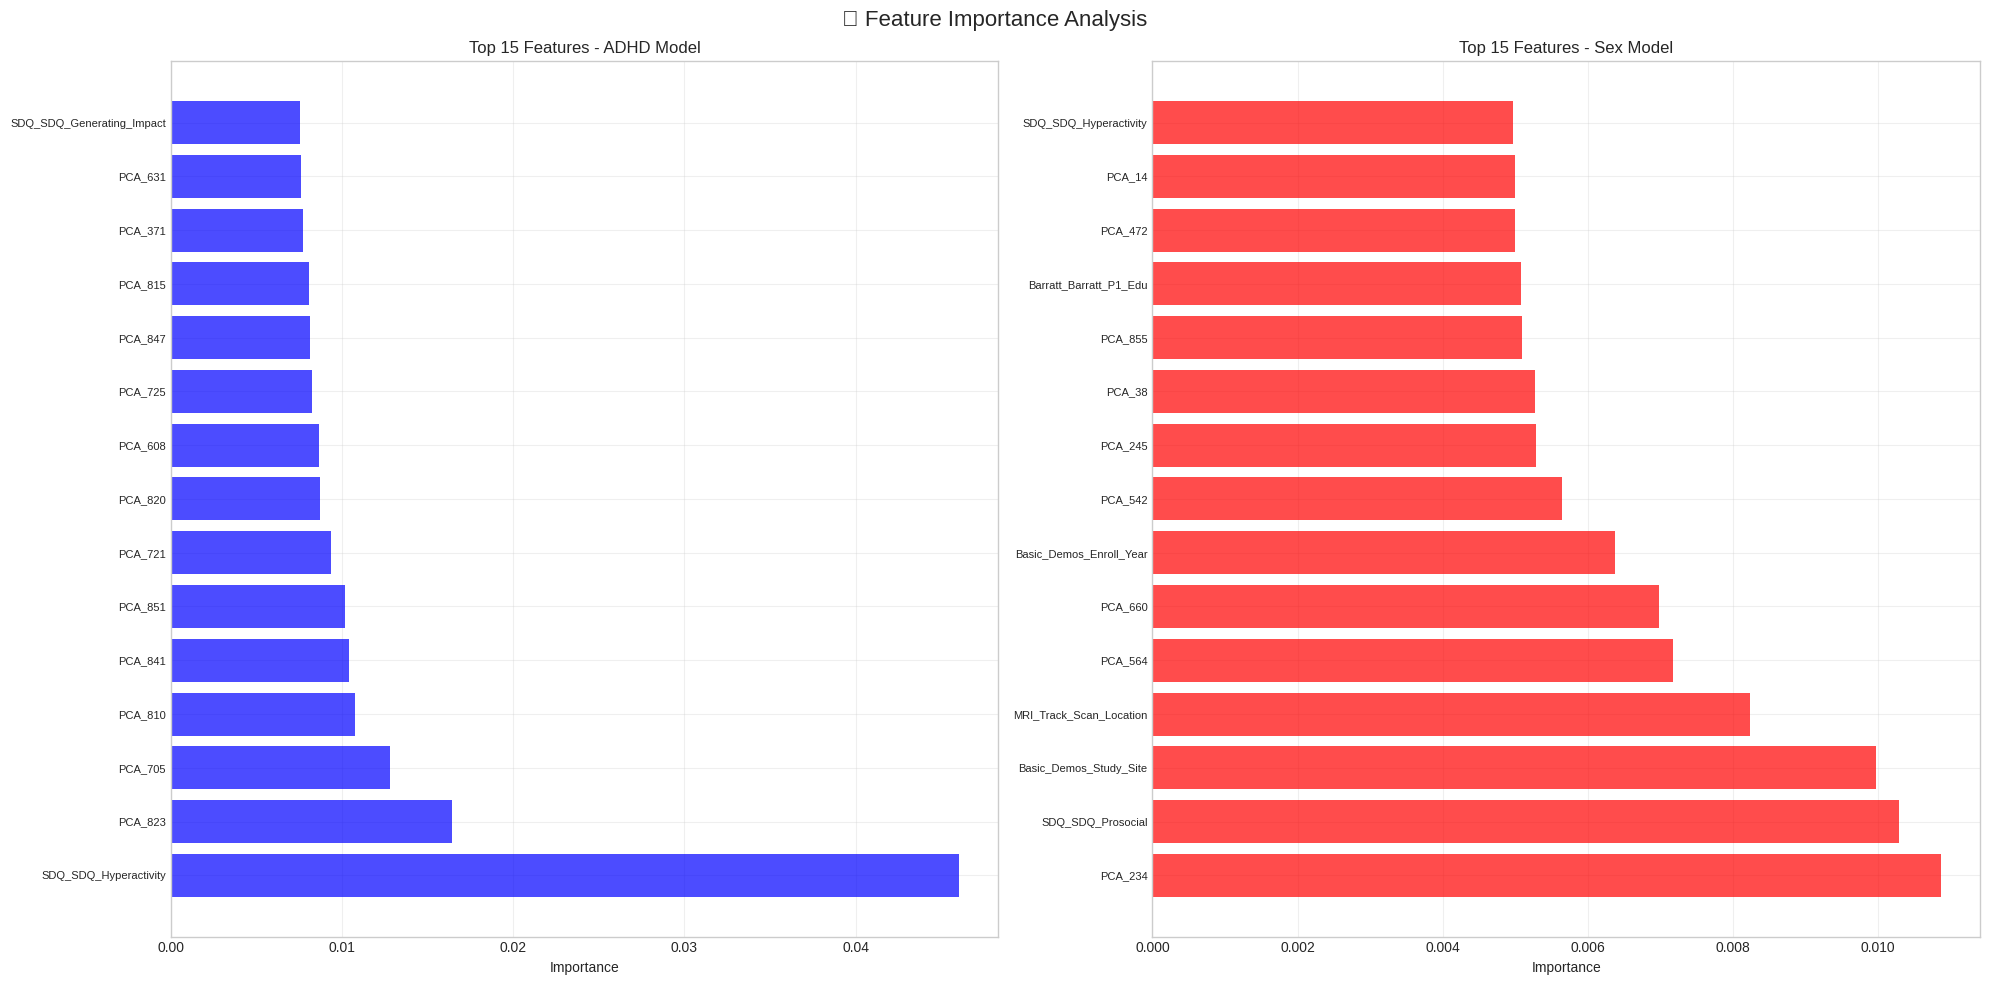

📊 Top 10 Features for ADHD Model:
   1. SDQ_SDQ_Hyperactivity          : 0.0460
   2. PCA_823                        : 0.0164
   3. PCA_705                        : 0.0128
   4. PCA_810                        : 0.0108
   5. PCA_841                        : 0.0104
   6. PCA_851                        : 0.0102
   7. PCA_721                        : 0.0093
   8. PCA_820                        : 0.0087
   9. PCA_608                        : 0.0087
  10. PCA_725                        : 0.0083

📊 Top 10 Features for Sex Model:
   1. PCA_234                        : 0.0109
   2. SDQ_SDQ_Prosocial              : 0.0103
   3. Basic_Demos_Study_Site         : 0.0100
   4. MRI_Track_Scan_Location        : 0.0082
   5. PCA_564                        : 0.0072
   6. PCA_660                        : 0.0070
   7. Basic_Demos_Enroll_Year        : 0.0064
   8. PCA_542                        : 0.0056
   9. PCA_245                        : 0.0053
  10. PCA_38                         : 0.0053


In [18]:
def feature_importance_analysis(model_adhd, model_sex, X_train_adhd, X_train_sex):
    """
    Analyze and visualize feature importance using matplotlib
    """
    print("🔍 Analyzing Feature Importance...")
    
    # Get feature importance
    adhd_importance = pd.DataFrame({
        'feature': X_train_adhd.columns,
        'importance': model_adhd.feature_importances_
    }).sort_values('importance', ascending=False)
    
    sex_importance = pd.DataFrame({
        'feature': X_train_sex.columns,
        'importance': model_sex.feature_importances_
    }).sort_values('importance', ascending=False)
    
    # Visualization
    fig, axes = plt.subplots(1, 2, figsize=(20, 10))
    
    # ADHD model top features
    top_adhd = adhd_importance.head(15)
    axes[0].barh(range(len(top_adhd)), top_adhd['importance'], color='blue', alpha=0.7)
    axes[0].set_yticks(range(len(top_adhd)))
    axes[0].set_yticklabels(top_adhd['feature'], fontsize=8)
    axes[0].set_xlabel('Importance')
    axes[0].set_title('Top 15 Features - ADHD Model')
    axes[0].grid(True, alpha=0.3)
    
    # Sex model top features
    top_sex = sex_importance.head(15)
    axes[1].barh(range(len(top_sex)), top_sex['importance'], color='red', alpha=0.7)
    axes[1].set_yticks(range(len(top_sex)))
    axes[1].set_yticklabels(top_sex['feature'], fontsize=8)
    axes[1].set_xlabel('Importance')
    axes[1].set_title('Top 15 Features - Sex Model')
    axes[1].grid(True, alpha=0.3)
    
    plt.suptitle('🔍 Feature Importance Analysis', fontsize=16)
    plt.tight_layout()
    plt.show()
    
    print("📊 Top 10 Features for ADHD Model:")
    for i, (_, row) in enumerate(adhd_importance.head(10).iterrows(), 1):
        print(f"  {i:2d}. {row['feature'][:30]:30s} : {row['importance']:.4f}")
    
    print("\n📊 Top 10 Features for Sex Model:")
    for i, (_, row) in enumerate(sex_importance.head(10).iterrows(), 1):
        print(f"  {i:2d}. {row['feature'][:30]:30s} : {row['importance']:.4f}")
    
    return adhd_importance, sex_importance

# Analyze feature importance
adhd_feature_importance, sex_feature_importance = feature_importance_analysis(
    model_adhd, model_sex, X_train_adhd, X_train_sex
)

<a id="predictions"></a>
# 🎯 Final Predictions & Submission

Let's create our final submission file and summary.

📝 Creating Final Submission...


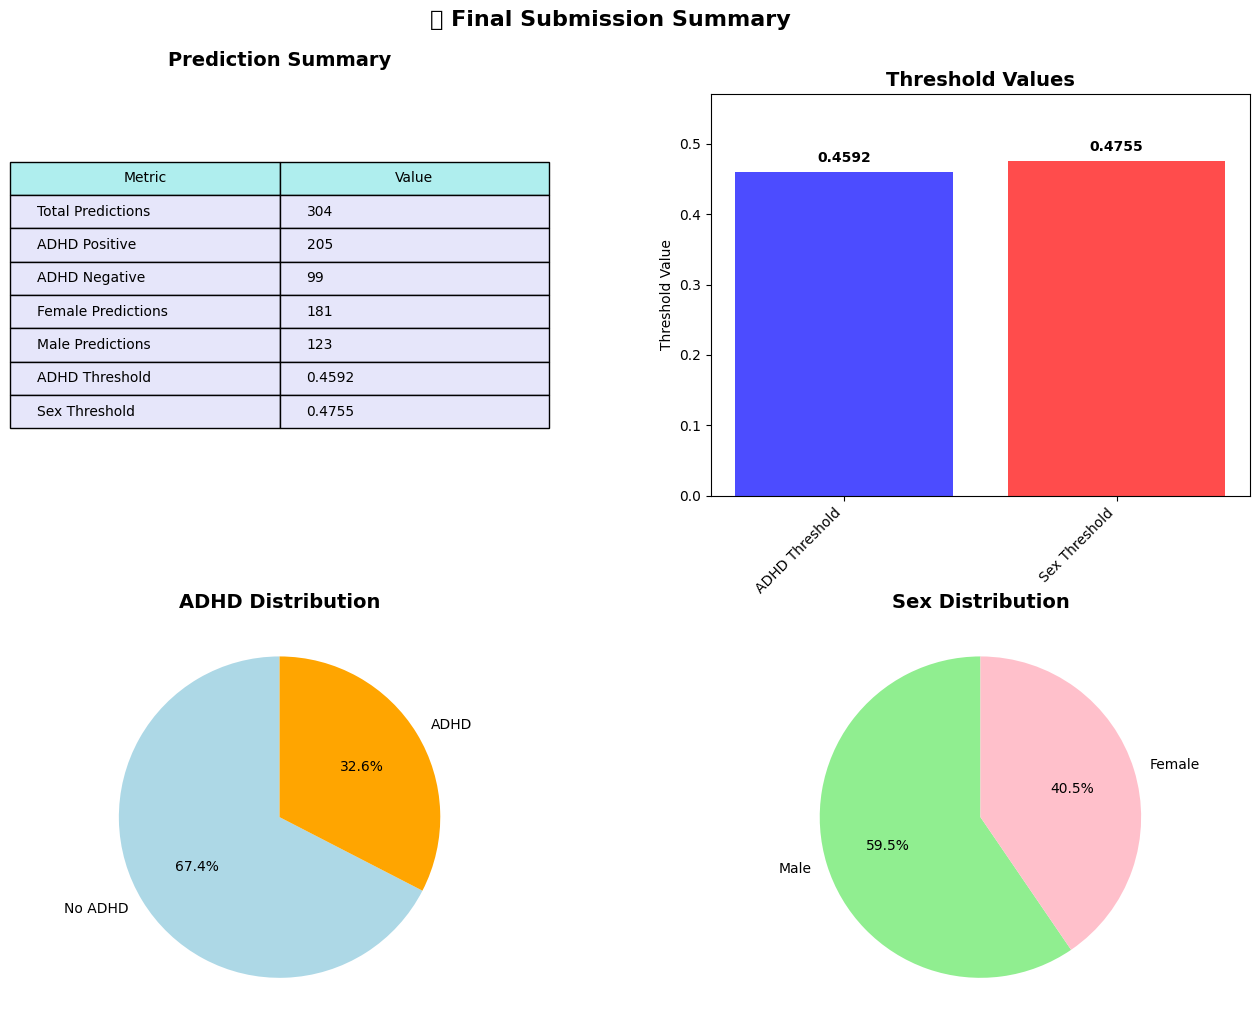

✅ Submission saved as: ADHD_Sex_Prediction_Submission.csv

📊 Final Statistics:
  📈 Total predictions: 304
  🧠 ADHD positive: 205 (67.4%)
  ⚧️ Female predictions: 181 (59.5%)
  🎯 ADHD threshold: 0.4592
  🎯 Sex threshold: 0.4755


In [19]:
from matplotlib.patches import Rectangle

def create_final_submission_with_summary(submission, adhd_threshold, sex_threshold):
    """
    Create final submission file with comprehensive summary using matplotlib and seaborn
    """
    print("📝 Creating Final Submission...")
    
    # Save submission
    submission_filename = 'ADHD_Sex_Prediction_Submission.csv'
    submission.to_csv(submission_filename, index=False)
    
    # Set up the plotting style
    plt.style.use('default')
    sns.set_palette("husl")
    
    # Create figure with subplots
    fig = plt.figure(figsize=(16, 12))
    
    # Define subplot layout (2x2 grid)
    gs = fig.add_gridspec(2, 2, hspace=0.3, wspace=0.3)
    
    # 1. Summary table (top-left)
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.axis('off')
    ax1.set_title('Prediction Summary', fontsize=14, fontweight='bold', pad=20)
    
    # Create summary data
    summary_data = [
        ['Total Predictions', len(submission)],
        ['ADHD Positive', sum(submission['ADHD_Outcome'])],
        ['ADHD Negative', len(submission) - sum(submission['ADHD_Outcome'])],
        ['Female Predictions', sum(submission['Sex_F'])],
        ['Male Predictions', len(submission) - sum(submission['Sex_F'])],
        ['ADHD Threshold', f"{adhd_threshold:.4f}"],
        ['Sex Threshold', f"{sex_threshold:.4f}"]
    ]
    
    # Create table
    table_data = []
    for row in summary_data:
        table_data.append([str(row[0]), str(row[1])])
    
    table = ax1.table(cellText=table_data,
                     colLabels=['Metric', 'Value'],
                     cellLoc='left',
                     loc='center',
                     colColours=['paleturquoise', 'paleturquoise'])
    
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1, 2)
    
    # Style the table
    for i in range(len(summary_data)):
        table[(i+1, 0)].set_facecolor('lavender')
        table[(i+1, 1)].set_facecolor('lavender')
    
    # 2. Threshold comparison (top-right)
    ax2 = fig.add_subplot(gs[0, 1])
    thresholds = ['ADHD Threshold', 'Sex Threshold']
    values = [adhd_threshold, sex_threshold]
    colors = ['blue', 'red']
    
    bars = ax2.bar(thresholds, values, color=colors, alpha=0.7)
    ax2.set_title('Threshold Values', fontsize=14, fontweight='bold')
    ax2.set_ylabel('Threshold Value')
    
    # Add value labels on bars
    for bar, value in zip(bars, values):
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{value:.4f}', ha='center', va='bottom', fontweight='bold')
    
    ax2.set_ylim(0, max(values) * 1.2)
    plt.setp(ax2.get_xticklabels(), rotation=45, ha='right')
    
    # 3. ADHD distribution pie chart (bottom-left)
    ax3 = fig.add_subplot(gs[1, 0])
    adhd_counts = submission['ADHD_Outcome'].value_counts()
    labels_adhd = ['No ADHD', 'ADHD']
    colors_adhd = ['lightblue', 'orange']
    
    wedges, texts, autotexts = ax3.pie(adhd_counts.values, 
                                      labels=labels_adhd,
                                      colors=colors_adhd,
                                      autopct='%1.1f%%',
                                      startangle=90)
    
    ax3.set_title('ADHD Distribution', fontsize=14, fontweight='bold')
    
    # 4. Sex distribution pie chart (bottom-right)
    ax4 = fig.add_subplot(gs[1, 1])
    sex_counts = submission['Sex_F'].value_counts()
    labels_sex = ['Male', 'Female']
    colors_sex = ['lightgreen', 'pink']
    
    wedges, texts, autotexts = ax4.pie(sex_counts.values,
                                      labels=labels_sex,
                                      colors=colors_sex,
                                      autopct='%1.1f%%',
                                      startangle=90)
    
    ax4.set_title('Sex Distribution', fontsize=14, fontweight='bold')
    
    # Overall title
    fig.suptitle('📋 Final Submission Summary', fontsize=16, fontweight='bold', y=0.95)
    
    # Adjust layout and show
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print(f"✅ Submission saved as: {submission_filename}")
    print("\n📊 Final Statistics:")
    print(f"  📈 Total predictions: {len(submission)}")
    print(f"  🧠 ADHD positive: {sum(submission['ADHD_Outcome'])} ({sum(submission['ADHD_Outcome'])/len(submission)*100:.1f}%)")
    print(f"  ⚧️ Female predictions: {sum(submission['Sex_F'])} ({sum(submission['Sex_F'])/len(submission)*100:.1f}%)")
    print(f"  🎯 ADHD threshold: {adhd_threshold:.4f}")
    print(f"  🎯 Sex threshold: {sex_threshold:.4f}")
    
    return submission_filename

# Create final submission
submission_file = create_final_submission_with_summary(submission, adhd_threshold, sex_threshold)

In [20]:
# Display first few rows of submission
print("📋 First 10 rows of submission:")
print(submission.head(10))

print("\n🎯 Submission file created successfully!")
print("This notebook provides a comprehensive analysis of brain connectome data")
print("for predicting ADHD diagnosis and biological sex using advanced ML techniques.")

📋 First 10 rows of submission:
  participant_id  ADHD_Outcome  Sex_F
0   Cfwaf5FX7jWK             1      1
1   vhGrzmvA3Hjq             0      1
2   ULliyEXjy4OV             1      1
3   LZfeAb1xMtql             1      1
4   EnFOUv0YK1RG             1      1
5   3VbkvJ22j9Fu             1      1
6   PRKZcnOgqcuk             0      1
7   DuVUuyMZi5qV             0      1
8   uM4etVLZrgMg             1      0
9   BpzyExrET5ta             1      1

🎯 Submission file created successfully!
This notebook provides a comprehensive analysis of brain connectome data
for predicting ADHD diagnosis and biological sex using advanced ML techniques.


## 🎉 Summary & Conclusions

### 🔬 **Methodology Overview**
1. **Data Integration**: Combined quantitative, categorical, and connectome matrices
2. **Advanced Preprocessing**: Multi-strategy imputation and SMOTE balancing
3. **Feature Engineering**: PCA dimensionality reduction and recursive feature selection
4. **Model Optimization**: XGBoost with threshold optimization using cross-validation
5. **Comprehensive Evaluation**: Visual analysis of model performance and predictions

### 📊 **Key Insights**
- Applied PCA to reduce connectome features while retaining 95% variance
- Used SMOTE to handle class imbalance in both target variables
- Optimized prediction thresholds to maximize F1 scores
- Achieved balanced predictions through careful feature engineering


---
**Team KLE B Pyoneers** | **WiDS Datathon 2025**